# Coupled Games Fourier Coefficients

Get Fourier coefficients for $\mathcal{H}$-functions. To be used to generate two-parameter bifurcation diagrams in XPP.


**Fourier notes**

Recall: Given the fourier coefficients $c_n$ for $n \in\mathbb{Z}$ and supposing that $c_n = a_n + i b_n$, the real Fourier series is given by,
$$\sum_{n =1}^\infty 2 a_n \cos(n \omega t) - 2 b_n \sin(n \omega t).$$
So I really only need to save the coefficients for positive frequencies and double them. 

Goal: given a function, display a list of coefficients (maybe implement text output to copy/past into XPP)

# Inits

In [1]:
import sys; sys.path.insert(0, '..') # add parent folder path where lib folder is
# user-defined

import couplingPI as cpi
import response as rp

from sirv2 import (rhs, coupling_social_eta, coupling_physical_eta, coupling_both_eta)
# from xppwrap import xpp_wrap

import contextlib

import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
import sympy as sym

from scipy.optimize import root,bisect
import copy
from copy import deepcopy
import os

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Helvetica"
})

Matrix = sym.Matrix
CPI = cpi.couplingPI
rsp = rp.Response

## kwargs

In [2]:
# simulation keyword arguments
kw_sim = {'rtol':1e-8,'atol':1e-8,'method':'LSODA'}

## Defs

In [3]:
def split_terms(expr):
    """Split expr at top-level +/- signs; each term keeps its sign. Skips exponents like 1e-5."""
    terms, depth, start = [], 0, 0
    for i, ch in enumerate(expr):
        if ch == '(':
            depth += 1
        elif ch == ')':
            depth -= 1
        elif ch in '+-' and depth == 0 and i > 0 and expr[i - 1] not in 'eE*/^(':
            terms.append(expr[start:i])
            start = i
    terms.append(expr[start:])
    return [t for t in terms if t]


def xpp_wrap(name, expr, arg='x', width=100):
    """Return XPP lines defining name(arg)=expr with every line <= width chars."""
    expr = expr.replace(' ', '')
    full = '{}({})={}'.format(name, arg, expr)
    if len(full) <= width:
        return [full]
    lines, helpers, chunk = [], [], ''
    for term in split_terms(expr):
        head = '{}p{}({})='.format(name, len(helpers), arg)
        if chunk and len(head + (chunk + term).lstrip('+')) > width:
            helpers.append(head[:-1])
            lines.append(head + chunk.lstrip('+'))
            chunk = term
        else:
            chunk += term
    head = '{}p{}({})='.format(name, len(helpers), arg)
    helpers.append(head[:-1])
    lines.append(head + chunk.lstrip('+'))
    lines.append('{}({})='.format(name, arg) + '+'.join(helpers))
    return lines

In [4]:
def get_coeffs(data,threshold = 0.1):
    coeffs = np.fft.fft(data)
    
    # get coeffs above threshold
    NH = len(data)
    
    coeffs_re_all = np.real(coeffs)
    coeffs_im_all = np.imag(coeffs)
    nn = np.arange(len(coeffs),dtype='int')
    
    coeffs_re_bool = (np.abs(coeffs_re_all) > threshold)*(nn<NH/2)
    coeffs_im_bool = (np.abs(coeffs_im_all) > threshold)*(nn<NH/2)
    
    freqs = np.fft.fftfreq(len(coeffs),d=(1/a.NH))
    
    coeffs_re = coeffs_re_all[coeffs_re_bool]
    coeffs_im = coeffs_im_all[coeffs_im_bool]
    
    freqs[coeffs_re_bool]

    return coeffs_re, coeffs_im, freqs[coeffs_re_bool], freqs[coeffs_im_bool]

def call_fourier_series(a,coeffs_re,coeffs_im,fr,fi):
    tot = 0
    for i,c in enumerate(coeffs_re):
        if fr[i] == 0:
            tot += c/a.NH
        else:
            tot += 2*c*np.cos(a.x*fr[i]/a.T*2*np.pi)/a.NH
    
    for i,c in enumerate(coeffs_im):
        tot += -2*c*np.sin(a.x*fi[i]/a.T*2*np.pi)/a.NH

    return tot

def print_fourier_series(a,coeffs_re,coeffs_im,fr,fi):
    # display copy/paste-able equation
    eq = ''
    for i,c in enumerate(coeffs_re):
        if fr[i] == 0:
            eq += '{:.4f}'.format(c/a.NH)
        else:
            eq += '+2*cos(x*{})*({:.4f})'.format(fr[i],c/a.NH)
    
    for i,c in enumerate(coeffs_im):
        eq += '-2*sin(x*{})*({:.4f})'.format(fi[i],c/a.NH)
    return eq


In [5]:
def print_fourier_series_tex(a,coeffs_re,coeffs_im,fr,fi):
    # display copy/paste-able equation
    eq = ''
    for i,c in enumerate(coeffs_re):
        if fr[i] == 0:
            eq += '{:.4f}'.format(c/a.NH)
        else:
            coeff = 2*c/a.NH
            if coeff < 0:
                sign = '-'
            else:
                sign = '+'
            eq += sign+'{:.4f}\\cos({}x) '.format(abs(coeff),int(fr[i]))
    
    for i,c in enumerate(coeffs_im):
        coeff = -2*c/a.NH
        if coeff < 0:
            sign = '-'
        else:
            sign = '+'
        eq += sign+'{:.4f}\\sin({}x) '.format(abs(coeff),int(fi[i]))
    return eq


## get jr parameters given C1

In [6]:
def get_pd():
    """model parameters for a single oscillator"""
    pd = dict(alpha = .01, beta = 0.5, gamma = 1/7, eta = 1/7,mu=0.01 , kappa = 300, rho = 0.01,psi = 0.5,  zeta=1,om=1,om_fix=1)
    return pd

## load sys

In [7]:
def load_system(kap=300,load_data_only=False,type1='social',par='eta',recompute_list=['']):

    #print(cc)

    # all het. parameters must be named, indexed, and ordered as shown!!
    # for oscillator 1: del_0, del_1, ...
    # for oscillator 2: sig_0, sig_1, ...
    # eps_i is created inside rsp.
    het_pars1 = ['del0','del1']
    het_pars2 = ['sig0','sig1']

    pardict = get_pd()
    pardict['kappa'] = kap
    # print(pardict)
    init0 = [0.17603663,
      0.829848,
      0.99917684]
    t = np.arange(0,1000,.01)
    out = solve_ivp(rhs,[t[0],t[-1]],init0,t_eval=t,args=(pardict,),**kw_sim)
    idxs = find_peaks(out.y[0])[0]
    per = np.diff(t[idxs])[-1]
    init = out.y.T[-1,:]
    init = np.append(init,per)

    if type1 in ['social']:
        if par in ['eta']:
            cc = coupling_social_eta
    elif type1 in ['physical']:
        if par in ['eta']:
            cc = coupling_physical_eta
    elif type1 in ['both']:
        if par in ['eta']:
            cc = coupling_both_eta
    else:
        raise ValueError('tf are you doing?')
    
    kwargs_jr = dict(var_names=['S', 'I', 'R'], 
                     pardict=copy.deepcopy(pardict), 
                     rhs=rhs,
                     coupling=cc,
                     TN=2000,
                     trunc_order=0,
                     init=init,
                     recompute_list=[],
                     z_forward=False,
                     i_forward=False,
                     i_bad_dx=[False,True,False,False],
                     lc_prominence=0.02,
                     max_iter=30,
                     save_fig=False,
                     max_time_lc=10000,
                     init_is_precise=False)
    
    # always use idx=0 for oscillator 1 and idx=1 for oscillator 2.
    system1=rsp(idx=0, model_name='sirv_0_'+type1+'k='+str(kap), het_pars=het_pars1, **copy.deepcopy(kwargs_jr))
    system2=rsp(idx=1, model_name='sirv_1_'+type1+'k='+str(kap), het_pars=het_pars2, **copy.deepcopy(kwargs_jr))
    
    kw_nm = {'system1':system1, 'system2':system2, 'NH':1024, 'save_fig':False,'recompute_list':recompute_list}
    a = CPI(**kw_nm)
    return a

In [8]:
def print_post():
    print('# oscillator 0 (at phi)  carries heterogeneity delta')
    print('# oscillator 1 (at -phi)')
    print('')
    print("phi'=s*(eps*(1-a)*h1(-phi)-eps*(1+a)*h1(phi)-b*h7(0))")
    print('')
    print('@ total=100,dt=0.02')
    print('@ dsmax=.01,dsmin=1e-5,ds=.001')
    print('@ parmin=-10,parmax=10')
    print('')
    print('d')

# eta

In [9]:
fname_template = 'ode/sirv2_redu_{}_{}_kap={}.ode'

## Social Only

### kappa = 300

In [10]:
kk = 300;
type1 = 'social'
par = 'eta'

In [11]:
a = load_system(kap=kk,load_data_only=False,type1=type1)

#### Fourier Coefficients

Only need to call oscillator 1 since only it contains the heterogeneity.

In [12]:
print(fname_template.format(type1,par,kk))
fname = fname_template.format(type1,par,kk)

ode/sirv2_redu_social_eta_kap=300.ode


In [13]:
# All print() output inside the with-block, including from print_post(), goes to the file.
# Note: the XPP parameter "a" in the first line is just text; the Python object `a` is unaffected.
called_series_a = []
thresholds = 12*[1]

with open(fname, 'w') as f, contextlib.redirect_stdout(f):
    print('p a=0, b=0, eps=.02')
    print('TT='+str(a.system1.T))
    print('s=TT/(2*pi)')
    print('k='+str(a.system1.kappa_val))

    for idx in [0,6]:
        data = a.system1.h['dat'][idx]
        coeffs_re, coeffs_im, fr, fi = get_coeffs(data,threshold=thresholds[idx])
        tot = call_fourier_series(a,coeffs_re,coeffs_im,fr,fi)
        called_series_a.append(tot)
        expr = print_fourier_series(a,coeffs_re,coeffs_im,fr,fi)
        print('\n'.join(xpp_wrap('h'+str(idx+1), str(expr))))

    print_post()

#### Plot

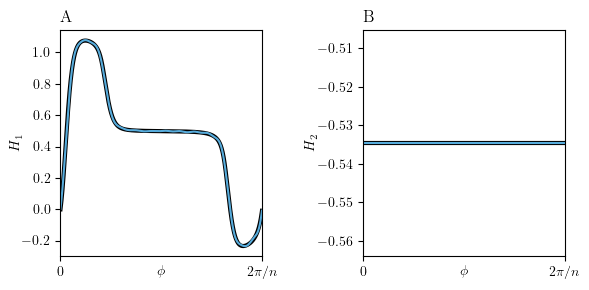

In [14]:
labels = ['A ','B ','C ','D ','E ','F ','G ','H' ,'I ','J ','K','L']
ylabels = [r'$H_'+str(i+1)+'$' for i in range(12)]

pi_label_short = [r"$0$", r"$2\pi/n$"]
import matplotlib
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['pgf.texsystem'] = 'pdflatex'
#matplotlib.rcParams['font.size'] = 12


preamble = (r'\usepackage{amsmath}'
            r'\usepackage{siunitx}'
            r'\usepackage{bm}'
            r'\newcommand{\ve}{\varepsilon}')

matplotlib.rcParams['text.latex.preamble'] = preamble
fontsize = 12

fig,axs = plt.subplots(1,2,figsize=(6,3))

axs = axs.flatten()

count = 0
for i in [0,6]:

    axs[count].plot(a.x,a.system1.h['dat'][i],color='k',lw=3)
    axs[count].plot(a.x,called_series_a[count]+np.zeros(len(a.x)),label = 'Approx.',color='#57acdc')
    count += 1

    #axs[1,i].plot(a.x,a.system2.h['dat'][i],color='k',lw=3)
    #axs[1,i].plot(a.x,called_series_b[i],label = 'Approx.',color='#57acdc')

for k in range(len(called_series_a)):
    label = labels[k]
    
    axs[k].set_xticks([0,a.T])
    axs[k].set_xticklabels(pi_label_short)

    axs[k].set_xlabel(r'$\phi$',labelpad=-10)
    axs[k].set_xlim(0,a.T)
    axs[k].set_ylabel(ylabels[k],labelpad=0)
    
    # title = label + r'$\quad\quad\quad$' + titles[k]
    axs[k].set_title(label,loc='left')

# axs[0].legend()

plt.tight_layout()
plt.subplots_adjust(wspace=.5,hspace=.5)
plt.savefig('fourier_vdp_thal{}{}.pdf'.format(a._n[1],a._m[1]))

# #axs

## Physical Only

### kappa = 300

In [15]:
kk = 300;
type1 = 'physical'
par = 'eta'

In [16]:
a = load_system(kap=kk,load_data_only=False,type1=type1)

iter=29, LC rel. err =1.43e-10                 
iter=29, LC rel. err =1.43e-10                 


#### Fourier Coefficients

Only need to call oscillator 1 since only it contains the heterogeneity.

In [17]:
print(fname_template.format(type1,par,kk))
fname = fname_template.format(type1,par,kk)

ode/sirv2_redu_physical_eta_kap=300.ode


In [18]:
# All print() output inside the with-block, including from print_post(), goes to the file.
# Note: the XPP parameter "a" in the first line is just text; the Python object `a` is unaffected.
called_series_a = []
thresholds = 12*[1]

with open(fname, 'w') as f, contextlib.redirect_stdout(f):
    print('p a=0, b=0, eps=.02')
    print('TT='+str(a.system1.T))
    print('s=TT/(2*pi)')
    print('k='+str(a.system1.kappa_val))

    for idx in [0,6]:
        data = a.system1.h['dat'][idx]
        coeffs_re, coeffs_im, fr, fi = get_coeffs(data,threshold=thresholds[idx])
        tot = call_fourier_series(a,coeffs_re,coeffs_im,fr,fi)
        called_series_a.append(tot)
        expr = print_fourier_series(a,coeffs_re,coeffs_im,fr,fi)
        print('\n'.join(xpp_wrap('h'+str(idx+1), str(expr))))

    print_post()

#### Plot

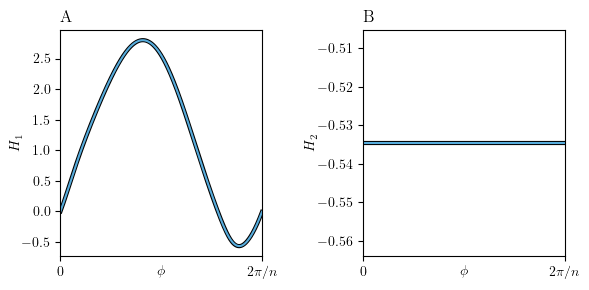

In [19]:
labels = ['A ','B ','C ','D ','E ','F ','G ','H' ,'I ','J ','K','L']
ylabels = [r'$H_'+str(i+1)+'$' for i in range(12)]

pi_label_short = [r"$0$", r"$2\pi/n$"]
import matplotlib
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['pgf.texsystem'] = 'pdflatex'
#matplotlib.rcParams['font.size'] = 12


preamble = (r'\usepackage{amsmath}'
            r'\usepackage{siunitx}'
            r'\usepackage{bm}'
            r'\newcommand{\ve}{\varepsilon}')

matplotlib.rcParams['text.latex.preamble'] = preamble
fontsize = 12

fig,axs = plt.subplots(1,2,figsize=(6,3))

axs = axs.flatten()

count = 0
for i in [0,6]:

    axs[count].plot(a.x,a.system1.h['dat'][i],color='k',lw=3)
    axs[count].plot(a.x,called_series_a[count]+np.zeros(len(a.x)),label = 'Approx.',color='#57acdc')
    count += 1

    #axs[1,i].plot(a.x,a.system2.h['dat'][i],color='k',lw=3)
    #axs[1,i].plot(a.x,called_series_b[i],label = 'Approx.',color='#57acdc')

for k in range(len(called_series_a)):
    label = labels[k]
    
    axs[k].set_xticks([0,a.T])
    axs[k].set_xticklabels(pi_label_short)

    axs[k].set_xlabel(r'$\phi$',labelpad=-10)
    axs[k].set_xlim(0,a.T)
    axs[k].set_ylabel(ylabels[k],labelpad=0)
    
    # title = label + r'$\quad\quad\quad$' + titles[k]
    axs[k].set_title(label,loc='left')

# axs[0].legend()

plt.tight_layout()
plt.subplots_adjust(wspace=.5,hspace=.5)
plt.savefig('fourier_vdp_thal{}{}.pdf'.format(a._n[1],a._m[1]))

# #axs

## Both

### kappa = 300

In [20]:
kk = 300;
type1 = 'both'
par = 'eta'

In [21]:
a = load_system(kap=kk,load_data_only=False,type1=type1)

iter=29, LC rel. err =1.43e-10                 
iter=29, LC rel. err =1.43e-10                 


#### Fourier Coefficients

Only need to call oscillator 1 since only it contains the heterogeneity.

In [22]:
print(fname_template.format(type1,par,kk))
fname = fname_template.format(type1,par,kk)

ode/sirv2_redu_both_eta_kap=300.ode


In [23]:
# All print() output inside the with-block, including from print_post(), goes to the file.
# Note: the XPP parameter "a" in the first line is just text; the Python object `a` is unaffected.
called_series_a = []
thresholds = 12*[1]

with open(fname, 'w') as f, contextlib.redirect_stdout(f):
    print('p a=0, b=0, eps=.02')
    print('TT='+str(a.system1.T))
    print('s=TT/(2*pi)')
    print('k='+str(a.system1.kappa_val))

    for idx in [0,6]:
        data = a.system1.h['dat'][idx]
        coeffs_re, coeffs_im, fr, fi = get_coeffs(data,threshold=thresholds[idx])
        tot = call_fourier_series(a,coeffs_re,coeffs_im,fr,fi)
        called_series_a.append(tot)
        expr = print_fourier_series(a,coeffs_re,coeffs_im,fr,fi)
        print('\n'.join(xpp_wrap('h'+str(idx+1), str(expr))))

    print_post()

#### Plot

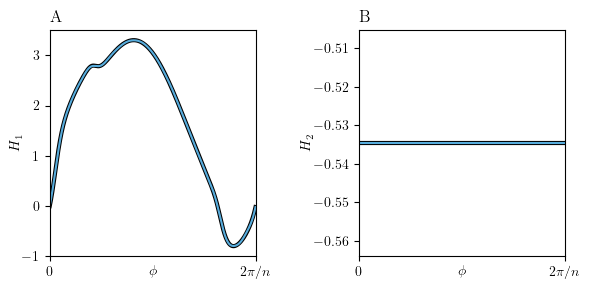

In [24]:
labels = ['A ','B ','C ','D ','E ','F ','G ','H' ,'I ','J ','K','L']
ylabels = [r'$H_'+str(i+1)+'$' for i in range(12)]

pi_label_short = [r"$0$", r"$2\pi/n$"]
import matplotlib
matplotlib.rcParams['font.family'] = 'serif'
matplotlib.rcParams['text.usetex'] = True
matplotlib.rcParams['pgf.texsystem'] = 'pdflatex'
#matplotlib.rcParams['font.size'] = 12


preamble = (r'\usepackage{amsmath}'
            r'\usepackage{siunitx}'
            r'\usepackage{bm}'
            r'\newcommand{\ve}{\varepsilon}')

matplotlib.rcParams['text.latex.preamble'] = preamble
fontsize = 12

fig,axs = plt.subplots(1,2,figsize=(6,3))

axs = axs.flatten()

count = 0
for i in [0,6]:

    axs[count].plot(a.x,a.system1.h['dat'][i],color='k',lw=3)
    axs[count].plot(a.x,called_series_a[count]+np.zeros(len(a.x)),label = 'Approx.',color='#57acdc')
    count += 1

    #axs[1,i].plot(a.x,a.system2.h['dat'][i],color='k',lw=3)
    #axs[1,i].plot(a.x,called_series_b[i],label = 'Approx.',color='#57acdc')

for k in range(len(called_series_a)):
    label = labels[k]
    
    axs[k].set_xticks([0,a.T])
    axs[k].set_xticklabels(pi_label_short)

    axs[k].set_xlabel(r'$\phi$',labelpad=-10)
    axs[k].set_xlim(0,a.T)
    axs[k].set_ylabel(ylabels[k],labelpad=0)
    
    # title = label + r'$\quad\quad\quad$' + titles[k]
    axs[k].set_title(label,loc='left')

# axs[0].legend()

plt.tight_layout()
plt.subplots_adjust(wspace=.5,hspace=.5)
plt.savefig('fourier_vdp_thal{}{}.pdf'.format(a._n[1],a._m[1]))

# #axs